In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/clean_ecommerce_data.csv')
df.head()


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_days,profit_margin_pct
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,3,16.00
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,3,30.00
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,4,47.00
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,7,-40.00
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,7,11.25


In [8]:
subcat_profit = df.groupby('sub_category')[['sales', 'profit']].sum().sort_values(by='profit')
print(subcat_profit)

                    sales      profit
sub_category                         
Tables        206965.5320 -17725.4811
Bookcases     114879.9963  -3472.5560
Supplies       46673.5380  -1189.0995
Fasteners       3024.2800    949.5182
Machines      189238.6310   3384.7569
Labels         12486.3120   5546.2540
Art            27118.7920   6527.7870
Envelopes      16476.4020   6964.1767
Furnishings    91705.1640  13059.1436
Appliances    107532.1610  18138.0054
Storage       223843.6080  21278.8264
Chairs        328449.1030  26590.1663
Binders       203412.7330  30221.7633
Paper          78479.2060  34053.5693
Accessories   167380.3180  41936.6357
Phones        330007.0540  44515.7306
Copiers       149528.0300  55617.8249


C:\Users\john\AppData\Local\Temp\ipykernel_13104\3017341905.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=subcat_profit['profit'], y=subcat_profit.index, palette=colors)


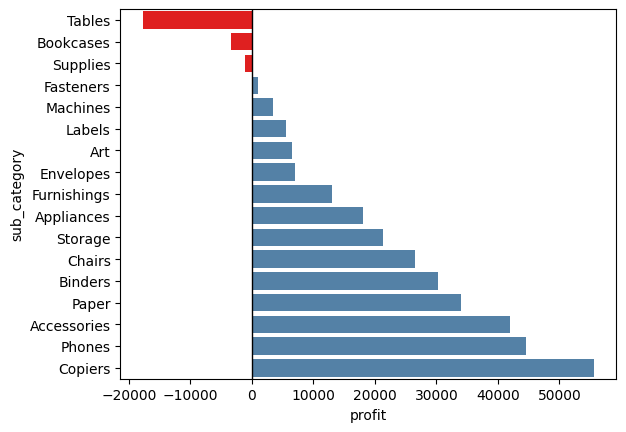

In [4]:
colors = ['red' if x < 0 else 'steelblue' for x in subcat_profit['profit']]
sns.barplot(x=subcat_profit['profit'], y=subcat_profit.index, palette=colors)
plt.axvline(0, color='black', linewidth=1)

In [7]:
discount_impact = df.groupby('discount')[['sales', 'profit', 'profit_margin_pct']].mean().round(2)
print(discount_impact)

           sales  profit  profit_margin_pct
discount                                   
0.00      226.74   66.90              34.02
0.10      578.40   96.06              15.58
0.15      529.97   27.29               3.42
0.20      209.08   24.70              17.68
0.30      454.74  -45.68             -11.55
0.32      536.79  -88.56             -17.43
0.40      565.13 -111.93             -22.25
0.45      498.63 -226.65             -45.46
0.50      892.71 -310.70             -54.91
0.60       48.15  -43.08             -68.91
0.70       97.18  -95.87             -79.47
0.80       56.55 -101.80            -182.50


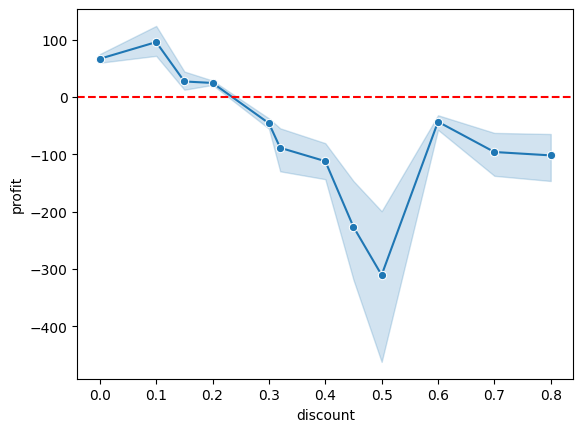

In [6]:
sns.lineplot(data=df, x='discount', y='profit', marker='o')
plt.axhline(0, color='red', linestyle='--')

In [9]:
region_summary = df.groupby('region')[['sales', 'profit', 'discount']].agg({
    'sales': 'sum',
    'profit': 'sum',
    'discount': 'mean'
}).round(2).sort_values(by='profit')

print(region_summary)

             sales     profit  discount
region                                 
Central  501239.89   39706.36      0.24
South    391721.90   46749.43      0.15
East     678781.24   91522.78      0.15
West     725457.82  108418.45      0.11


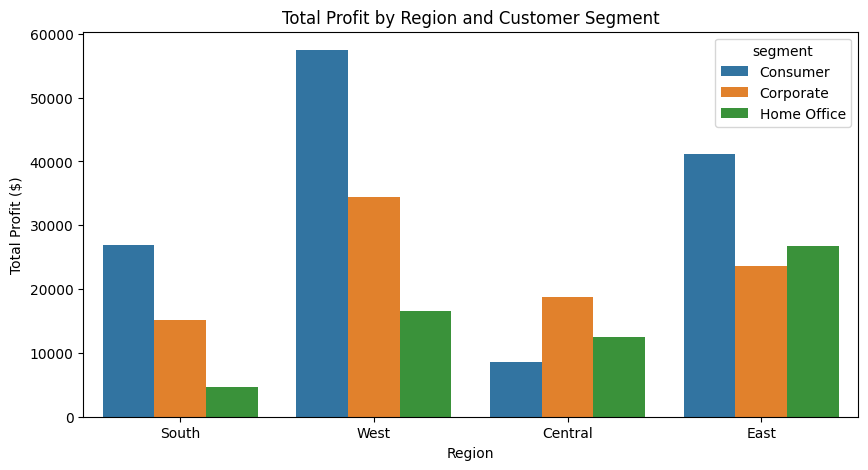

In [10]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='region', y='profit', hue='segment', estimator=sum, errorbar=None)
plt.title('Total Profit by Region and Customer Segment')
plt.xlabel('Region')
plt.ylabel('Total Profit ($)')
plt.show()


### Exploratory Data Analysis & Profit Leakage Identification (Python)

**1. Product Sub-Category Profitability (`sub_category`)**
* Aggregated total sales and total profit across all 17 product sub-categories and visualized losses using a color-coded horizontal bar chart.
* **Key Finding:** Three sub-categories are operating at a net loss—**Tables (`-$17,725.48`)**, **Bookcases (`-$3,472.56`)**, and **Supplies (`-$1,189.10`)**—despite Tables generating over `$206,965` in revenue, indicating severe margin erosion.
* **Top Performers:** **Copiers (`+$55,617.82`)**, **Phones (`+$44,515.73`)**, and **Accessories (`+$41,936.64`)** drive the highest net profit.

**2. Discount Threshold & Margin Erosion Analysis (`discount`)**
* Evaluated average order profit and profit margin percentage across all discount tiers (`0%` to `80%`) using `groupby` aggregations and a Seaborn trend line.
* **Key Finding:** Orders with **0% to 20% discounts remain profitable** (averaging `+$24.70` to `+$96.06` per order), whereas **discounts of 30% or higher immediately push average profit below `$0`**, reaching an average loss of **`-$310.70` per order at a 50% discount**.

**3. Regional & Customer Segment Performance (`region` & `segment`)**
* Compared total sales, total profit, and average discount rates across the four U.S. sales regions and three customer segments (`Consumer`, `Corporate`, `Home Office`).
* **Key Finding:** The **Central region** generated the lowest total profit (**`$39,706.36`**) despite out-selling the South region (`$501,239.89` vs. `$391,721.90`), directly driven by Central's significantly higher average discount rate (**`24%`** compared to `11%` in the West and `15%` in the East and South).
